# Predicting TSS from Landsat with Machine Learning (AquaSat)
**Goal:** predict total suspended solids (TSS, mg/L) from Landsat surface reflectance.
**Models:** Linear Regression (baseline) · Random Forest · XGBoost
**Flow:** 1 Load → 2 Clean → 3 Features + Target → 4 Split by site → 5 Compare models (CV) → 6 Pick best → 7 Final test → 8 Explain

**How to use:** put your AquaSat CSV in the same folder, set `CSV_PATH` below, then *Run All*.
If the file is not found, the notebook runs on **synthetic demo data** shaped like AquaSat, only to check the code works. **Never report demo numbers as results.**

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import xgboost as xgb, shap
warnings.filterwarnings("ignore")

# ---------------- settings (edit these) ----------------
CSV_PATH  = "aquasat.csv"   # your AquaSat matchup file
MAX_ROWS  = 100_000         # sample for speed on a laptop; None = use all rows
SEED      = 0
# Quality filters: STARTING POINTS. Look at the describe() table in step 2, then adjust.
FILTERS = dict(
    qa_water_only = True,   # keep pixels whose QA code is 68 (= water, low cloud confidence)
    min_pwater    = 80,     # % of surrounding pixels that are water
    max_clouds    = 50,     # % cloud cover of the scene
    max_timediff  = None,   # hours between sample and image; None = no filter
)
# --------------------------------------------------------

BANDS = ["blue", "green", "red", "nir", "swir1", "swir2"]
COLORS = dict(base="#c49a7a", rf="#7fc27c", xgb="#76634f", ink="#7f5c40")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": COLORS["ink"], "axes.labelcolor": COLORS["ink"],
                     "xtick.color": COLORS["ink"], "ytick.color": COLORS["ink"], "text.color": COLORS["ink"],
                     "font.size": 12})
os.makedirs("figures", exist_ok=True)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load data

In [2]:
def make_demo(n=60_000, n_sites=600, seed=SEED):
    """Synthetic rows with the same columns/scales as AquaSat. For testing the code only."""
    rng = np.random.default_rng(seed)
    site = rng.integers(0, n_sites, n)
    tss = np.exp(rng.normal(2.3, 1.1, n) + rng.normal(0, .3, n_sites)[site])
    s = tss / (tss + 40)
    def band(base, gain, p=1, sd=.006):
        return np.round((base + gain * s**p + rng.normal(0, sd, n)) * 10_000)
    df = pd.DataFrame(dict(
        SiteID=site, blue=band(.03, .03), green=band(.04, .06), red=band(.02, .14),
        nir=band(.01, .10, 1.5), swir1=band(.008, .04, 2), swir2=band(.006, .03, 2),
        qa=rng.choice([68, 66, 68, 68, 72], n), pwater=rng.uniform(60, 100, n),
        clouds=rng.uniform(0, 80, n), timediff=rng.uniform(0, 30, n), tss=tss))
    df.loc[rng.random(n) < .5, "tss"] = np.nan          # many rows have no TSS, like the real file
    return df

if os.path.exists(CSV_PATH):
    raw = pd.read_csv(CSV_PATH, low_memory=False)
    DEMO = False
else:
    raw = make_demo()
    DEMO = True
print("DEMO DATA (not real results)" if DEMO else f"Loaded {CSV_PATH}")
print("rows:", len(raw), "| rows with TSS:", raw.tss.notna().sum(), "| sites with TSS:", raw.loc[raw.tss.notna(), "SiteID"].nunique())

DEMO DATA (not real results)
rows: 60000 | rows with TSS: 30127 | sites with TSS: 600


## 2. Clean
Keep rows with TSS, convert bands to reflectance (× 0.0001), apply quality filters. The table shows how many rows survive each step.

In [3]:
df = raw.copy()
log = [("start", len(df))]
df = df[df.tss.notna() & (df.tss > 0)];                       log.append(("has TSS > 0", len(df)))
df[BANDS] = df[BANDS] * 0.0001                                 # stored ×10,000 → real reflectance
df = df[(df[BANDS] > 0).all(axis=1)];                         log.append(("all bands > 0", len(df)))
if FILTERS["qa_water_only"]:
    df = df[df.qa.round() == 68];                              log.append(("QA = water (68)", len(df)))
if FILTERS["min_pwater"] is not None:
    df = df[df.pwater >= FILTERS["min_pwater"]];               log.append((f"pwater ≥ {FILTERS['min_pwater']}%", len(df)))
if FILTERS["max_clouds"] is not None:
    df = df[df.clouds <= FILTERS["max_clouds"]];               log.append((f"clouds ≤ {FILTERS['max_clouds']}%", len(df)))
if FILTERS["max_timediff"] is not None:
    df = df[df.timediff.abs() <= FILTERS["max_timediff"]];     log.append((f"|timediff| ≤ {FILTERS['max_timediff']} h", len(df)))
if MAX_ROWS and len(df) > MAX_ROWS:
    df = df.sample(MAX_ROWS, random_state=SEED);               log.append((f"sample {MAX_ROWS:,}", len(df)))
df = df.reset_index(drop=True)
display(pd.DataFrame(log, columns=["step", "rows left"]))
display(df[["tss", "timediff", "clouds", "pwater", "qa"] + BANDS].describe().round(3))

,step,rows left
0,start,60000
1,has TSS > 0,30127
2,all bands > 0,25599
3,QA = water (68),15283
4,pwater ≥ 80%,7600
5,clouds ≤ 50%,4771


,tss,timediff,clouds,pwater,qa,blue,green,red,nir,swir1,swir2
count,4771.000,4771.000,4771.000,4771.000,4771.0,4771.000,4771.000,4771.000,4771.000,4771.000,4771.000
mean,21.494,15.020,25.103,90.021,68.0,0.038,0.056,0.057,0.026,0.013,0.010
std,53.274,8.650,14.500,5.743,0.0,0.008,0.013,0.027,0.017,0.008,0.006
min,0.243,0.000,0.006,80.000,68.0,0.014,0.024,0.006,0.000,0.000,0.000
25%,5.205,7.652,12.333,85.164,68.0,0.032,0.046,0.036,0.014,0.007,0.005
50%,11.142,15.044,24.942,89.965,68.0,0.037,0.054,0.051,0.022,0.012,0.009
75%,23.521,22.414,38.009,94.923,68.0,0.043,0.063,0.072,0.034,0.017,0.014
max,2826.231,29.997,49.998,99.996,68.0,0.071,0.114,0.164,0.111,0.053,0.040


## 3. Features + Target
**Never** use other field measurements (`chl_a`, `doc`, `secchi`, `tis`, `p_sand`) or `lat`/`long` as features.

11 features: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'NDWI', 'NDTI', 'R_G', 'R_B', 'NIR_R']


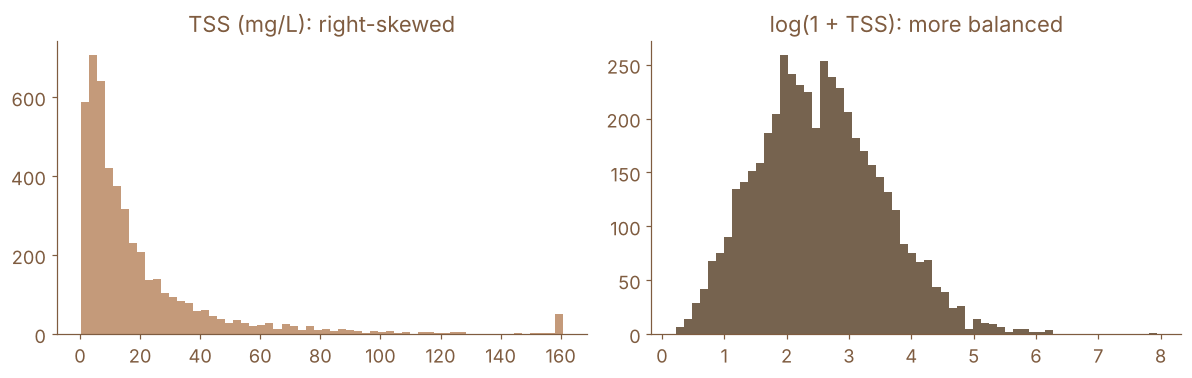

In [4]:
def add_features(d):
    d = d.copy()
    d["NDWI"]  = (d.green - d.nir) / (d.green + d.nir)
    d["NDTI"]  = (d.red - d.green) / (d.red + d.green)
    d["R_G"]   = d.red / d.green
    d["R_B"]   = d.red / d.blue
    d["NIR_R"] = d.nir / d.red
    return d

df = add_features(df)
FEATS = BANDS + ["NDWI", "NDTI", "R_G", "R_B", "NIR_R"]
X, y, groups = df[FEATS], np.log1p(df.tss), df.SiteID          # target: log(1 + TSS)
print(f"{len(FEATS)} features:", FEATS)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(df.tss.clip(upper=df.tss.quantile(.99)), bins=60, color=COLORS["base"]); ax[0].set_title("TSS (mg/L): right-skewed")
ax[1].hist(y, bins=60, color=COLORS["xgb"]); ax[1].set_title("log(1 + TSS): more balanced")
plt.tight_layout(); plt.savefig("figures/1_target_distribution.png", dpi=200, transparent=True); plt.show()

## 4. Split by site
20% of **sites** are locked away as the final test. All model comparison happens on the other 80%.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr, te = next(gss.split(X, y, groups))
X_tr, y_tr, g_tr = X.iloc[tr], y.iloc[tr], groups.iloc[tr]
X_te, y_te       = X.iloc[te], y.iloc[te]
print(f"train: {len(tr):,} rows / {g_tr.nunique()} sites   |   test: {len(te):,} rows / {groups.iloc[te].nunique()} sites")
assert set(g_tr) .isdisjoint(set(groups.iloc[te])), "a site is in both train and test!"

train: 3,795 rows / 480 sites   |   test: 976 rows / 120 sites


## 5. Compare 3 models with spatial cross-validation (train set only)

In [6]:
models = {
    "Linear Regression": (["NDTI"], LinearRegression()),
    "Random Forest":     (FEATS, RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED)),
    "XGBoost":           (FEATS, xgb.XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05,
                                                  subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=SEED)),
}

def scores(y_log, p_log):
    obs, pred = np.expm1(y_log), np.expm1(p_log)
    return dict(R2_log=r2_score(y_log, p_log),
                RMSE_log=mean_squared_error(y_log, p_log) ** .5,
                MAE_mgL=mean_absolute_error(obs, pred),
                MedAPE_pct=np.median(np.abs(pred - obs) / obs) * 100)

cv = GroupKFold(n_splits=5)
rows, oof = [], {}
for name, (cols, m) in models.items():
    p = cross_val_predict(m, X_tr[cols], y_tr, cv=cv, groups=g_tr)
    oof[name] = p
    fold_r2 = [r2_score(y_tr.iloc[t], p[t]) for _, t in cv.split(X_tr, y_tr, g_tr)]
    rows.append(dict(model=name, **scores(y_tr, p), R2_fold_sd=np.std(fold_r2)))
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,R2_log,RMSE_log,MAE_mgL,MedAPE_pct,R2_fold_sd
model,,,,,
Linear Regression,0.642,0.599,11.430,40.091,0.019
Random Forest,0.937,0.251,3.843,15.056,0.003
XGBoost,0.936,0.253,3.792,14.810,0.003


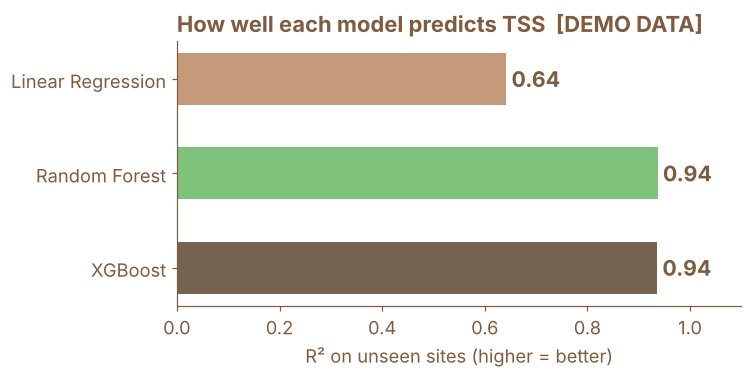

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
cols = [COLORS["base"], COLORS["rf"], COLORS["xgb"]]
bars = ax.barh(cv_table.index[::-1], cv_table.R2_log[::-1], color=cols[::-1], height=.55)
for b, v in zip(bars, cv_table.R2_log[::-1]):
    ax.text(v + .01, b.get_y() + b.get_height()/2, f"{v:.2f}", va="center", fontsize=14, fontweight="bold")
ax.set_xlim(0, 1.1); ax.set_xlabel("R² on unseen sites (higher = better)")
ax.set_title("How well each model predicts TSS" + ("  [DEMO DATA]" if DEMO else ""), loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("figures/2_model_comparison.png", dpi=200, transparent=True); plt.show()

## 6. Pick the best model
Chosen by mean CV R². If two models are within the fold-to-fold spread (`R2_fold_sd`), treat them as a tie.

In [8]:
best_name = cv_table.R2_log.idxmax()
gap = cv_table.R2_log.sort_values().iloc[-1] - cv_table.R2_log.sort_values().iloc[-2]
print("best:", best_name, f"| lead over runner-up: {gap:.3f} | fold spread: {cv_table.loc[best_name, 'R2_fold_sd']:.3f}")
if gap < cv_table.loc[best_name, "R2_fold_sd"]:
    print("→ the lead is smaller than the fold spread: report it as roughly a tie.")

best: Random Forest | lead over runner-up: 0.001 | fold spread: 0.003
→ the lead is smaller than the fold spread: report it as roughly a tie.


## 7. Final test (touch the test set once)

Random Forest on 120 never-seen sites:
R2_log         0.936
RMSE_log       0.248
MAE_mgL        3.039
MedAPE_pct    15.832


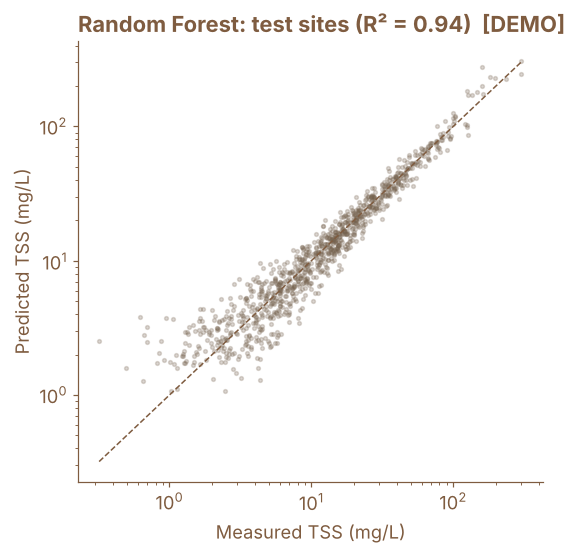

In [9]:
cols, best = models[best_name]
best.fit(X_tr[cols], y_tr)
p_te = best.predict(X_te[cols])
final = pd.Series(scores(y_te, p_te)).round(3)
print(f"{best_name} on {groups.iloc[te].nunique()} never-seen sites:"); print(final.to_string())

obs, pred = np.expm1(y_te), np.expm1(p_te)
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(obs, pred, s=6, alpha=.25, color=COLORS["xgb"])
lo, hi = max(.1, min(obs.min(), pred.min())), max(obs.max(), pred.max())
ax.plot([lo, hi], [lo, hi], "--", color=COLORS["ink"], lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Measured TSS (mg/L)"); ax.set_ylabel("Predicted TSS (mg/L)")
ax.set_title(f"{best_name}: test sites (R² = {final.R2_log:.2f})" + ("  [DEMO]" if DEMO else ""), loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("figures/3_predicted_vs_measured.png", dpi=200, transparent=True); plt.show()

## 8. Explain: which signals does the model use?
Tree models → SHAP. Linear model → its coefficient. Check whether the top features make physical sense (sediment reflects red light).

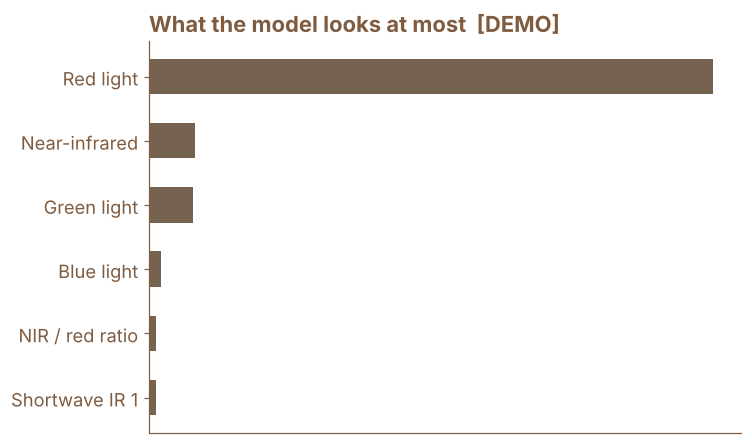

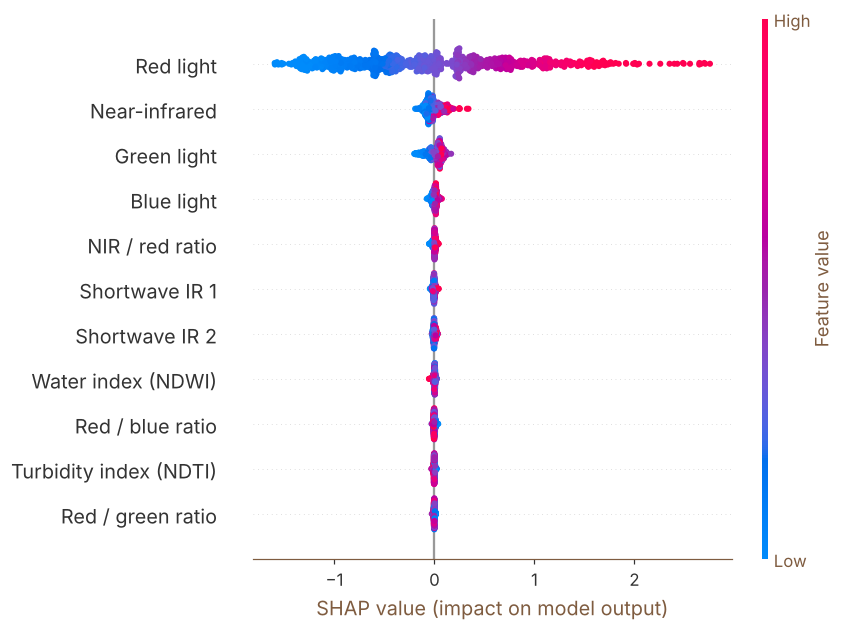

In [10]:
NICE = dict(blue="Blue light", green="Green light", red="Red light", nir="Near-infrared", swir1="Shortwave IR 1",
            swir2="Shortwave IR 2", NDWI="Water index (NDWI)", NDTI="Turbidity index (NDTI)",
            R_G="Red / green ratio", R_B="Red / blue ratio", NIR_R="NIR / red ratio")

if best_name == "Linear Regression":
    print(f"log(1+TSS) = {best.intercept_:.3f} + {best.coef_[0]:.3f} × NDTI")
else:
    Xs = X_te[cols].sample(min(2000, len(X_te)), random_state=SEED)
    sv = shap.TreeExplainer(best).shap_values(Xs)
    imp = pd.Series(np.abs(sv).mean(0), index=cols).sort_values()
    fig, ax = plt.subplots(figsize=(7, 4.2))
    top = imp.tail(6)
    ax.barh([NICE[c] for c in top.index], top.values, color=COLORS["xgb"], height=.55)
    ax.set_xticks([]); ax.set_title("What the model looks at most" + ("  [DEMO]" if DEMO else ""), loc="left", fontweight="bold")
    plt.tight_layout(); plt.savefig("figures/4_shap_importance.png", dpi=200, transparent=True); plt.show()
    shap.summary_plot(sv, Xs.rename(columns=NICE), show=False)
    plt.tight_layout(); plt.savefig("figures/5_shap_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()

## Results summary (copy to slides)
Fill from the outputs above. Slide 04 uses the CV table + final test; slide 05 uses the SHAP chart.
Figures are saved in `figures/` with transparent backgrounds.

In [11]:
print("DEMO DATA: do not report" if DEMO else "REAL DATA")
print(cv_table[["R2_log", "RMSE_log", "MAE_mgL", "MedAPE_pct"]].to_string())
print(f"\nFinal test ({best_name}): R² = {final.R2_log}, median error = {final.MedAPE_pct}%")

DEMO DATA: do not report
                   R2_log  RMSE_log  MAE_mgL  MedAPE_pct
model                                                   
Linear Regression   0.642     0.599   11.430      40.091
Random Forest       0.937     0.251    3.843      15.056
XGBoost             0.936     0.253    3.792      14.810

Final test (Random Forest): R² = 0.936, median error = 15.832%
